# Serie III · Auditoría del EDA de FAOSTAT, caña

Este análisis responde a la calidad y comparabilidad del inciso 1 antes de segmentar.
El periodo requerido es **1961–2023**; la fuente contiene también 2024, que se conserva fuera del análisis.
Todas las exclusiones de ámbito se exportan con valores, flags, código, año y motivo. Ningún extremo se elimina por su magnitud.
El generador anterior y notebook original quedan como respaldo local en outputs/serie3_eda/revision/respaldo/.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from scripts.auditar_faostat_serie3 import auditar
resultado = auditar(raiz)
resumen = resultado['resumen']
paises, cobertura = resultado['paises'], resultado['cobertura']
calidad, coherencia = resultado['calidad'], resultado['coherencia']
salida = raiz / 'outputs/serie3_eda/revision'
display(pd.Series({k:v for k,v in resumen.items() if k not in ['huellas_fuentes','anos_en_fuente']}, name='Auditoría'))

filas_cana_ancha                                                                         432
areas_totales                                                                            144
periodo_analisis                                                                [1961, 2023]
celdas_totales                                                                         27648
celdas_paises                                                                          21168
celdas_fuera_ambito                                                                     6480
areas_en_ambito                                                                          112
unidades                                   {'Area harvested': ['ha'], 'Production': ['t']...
baja_cobertura_filas                                                                      12
baja_cobertura_areas                                                                       4
celdas_sin_valor                                                      

## Ámbito, unidades y fuentes

Se comprueba clave área/elemento única, códigos presentes en diccionario, kg/ha para rendimiento, ha para área y t para producción. La versión NOFLAG coincide numéricamente con la versión de flags en todas las celdas de caña, incluidas ausencias; no se completa una usando la otra.

Una sola selección de países/territorios se utiliza para cobertura, calidad, extremos y gráficos: códigos menores de 5000, sin China agregado ni entidades históricas. Los componentes de China permanecen por separado. No se empalma Sudán/Etiopía con predecesores como si fuesen un país inmutable. Para comprobar el balance mundial histórico sí se consideran predecesores en sus años, manteniendo una vista distinta y explícita. No se interpreta exclusión de ámbito como dato erróneo.

,celdas,areas
motivo_fuera_ambito,,
agregado_China_componentes_separados,189,1
agregado_China_componentes_separados;ano_fuera_1961_2023,3,1
agregado_regional_o_grupo,5481,29
agregado_regional_o_grupo;ano_fuera_1961_2023,87,29
ano_fuera_1961_2023,336,112
entidad_historica_no_empalmada,378,2
entidad_historica_no_empalmada;ano_fuera_1961_2023,6,2


,codigo_area,area,elemento,n_anos,n_ceros,n_flags_no_oficiales,baja_cobertura
36,26,Brunei Darussalam,Area harvested,4,0,4,True
37,26,Brunei Darussalam,Production,4,0,0,True
38,26,Brunei Darussalam,Yield,4,0,4,True
159,118,Kuwait,Area harvested,3,3,3,True
160,118,Kuwait,Production,3,0,0,True
161,118,Kuwait,Yield,3,0,3,True
201,155,Vanuatu,Area harvested,2,0,2,True
202,155,Vanuatu,Production,2,0,1,True
203,155,Vanuatu,Yield,2,0,2,True
252,189,Saint Lucia,Area harvested,6,1,2,True


Áreas con algún indicador de baja cobertura: 4


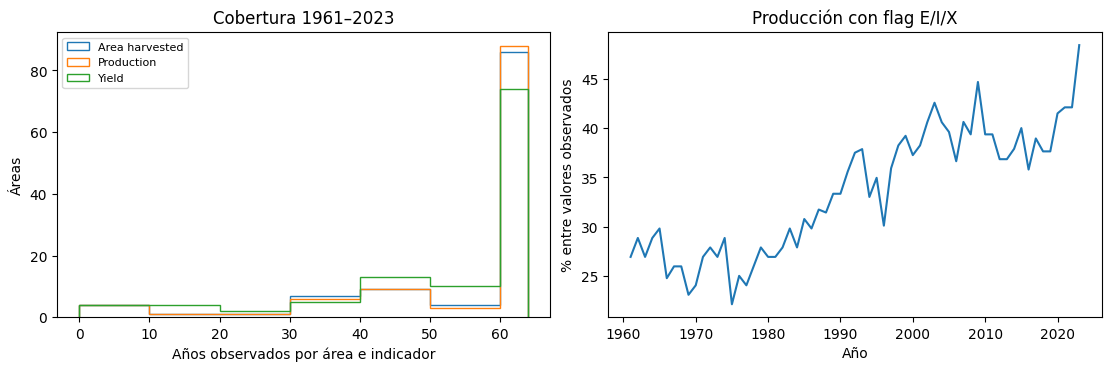

,ano,n_areas,n_observadas,n_ausentes,n_no_oficiales,n_sin_flag,proporcion_no_oficial
0,1961,112,104,8,28,0,0.269231
62,2023,112,95,17,46,0,0.484211


In [2]:
fuera = pd.read_csv(salida / 'filas_fuera_ambito.csv')
display(fuera.groupby('motivo_fuera_ambito').agg(celdas=('valor','size'), areas=('area','nunique')))
display(cobertura[cobertura.baja_cobertura])
print('Áreas con algún indicador de baja cobertura:', cobertura.loc[cobertura.baja_cobertura, 'area'].nunique())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for elemento, g in cobertura.groupby('elemento'):
    axes[0].hist(g.n_anos, bins=[0,10,20,30,40,50,60,64], histtype='step', label=elemento)
axes[0].set(xlabel='Años observados por área e indicador', ylabel='Áreas', title='Cobertura 1961–2023')
axes[0].legend(fontsize=8)
axes[1].plot(calidad.ano, 100*calidad.proporcion_no_oficial)
axes[1].set(xlabel='Año', ylabel='% entre valores observados', title='Producción con flag E/I/X')
fig.savefig(salida / 'cobertura_calidad.png', dpi=150)
plt.show()
display(calidad.iloc[[0,-1]])

## Calidad: denominador y ausencia

La proporción E/I/X se calcula **sobre producción con valor observado**, sin convertir NaN a texto. Se reportan observados, ausentes y valores sin flag por separado. El flag M significa que el dato falta/no puede existir según el diccionario; no se convierte en cero ni se asume ausencia aleatoria. Se conserva el código de flag original.

Menos de diez años marca baja cobertura para revisión, sin excluir por ahora esas áreas. La selección final de ventanas comunes y cobertura mínima pertenece a la segmentación; no se rellena con ceros o interpolación para forzar 63 observaciones por país.

Máxima diferencia relativa mundial 1961–2023: 2.1764941918708228e-11
Máxima diferencia China/componentes: 0.0


,ano,suma_territorios,World,diferencia_t,diferencia_relativa,china_menos_componentes_t
61,2022,1.921167e+09,1.921167e+09,2.384186e-07,1.241009e-16,0.0
62,2023,2.017376e+09,2.017376e+09,-1.999974e-02,-9.913739e-12,0.0
63,2024,1.932685e+09,1.939782e+09,-7.097206e+06,-3.658765e-03,0.0


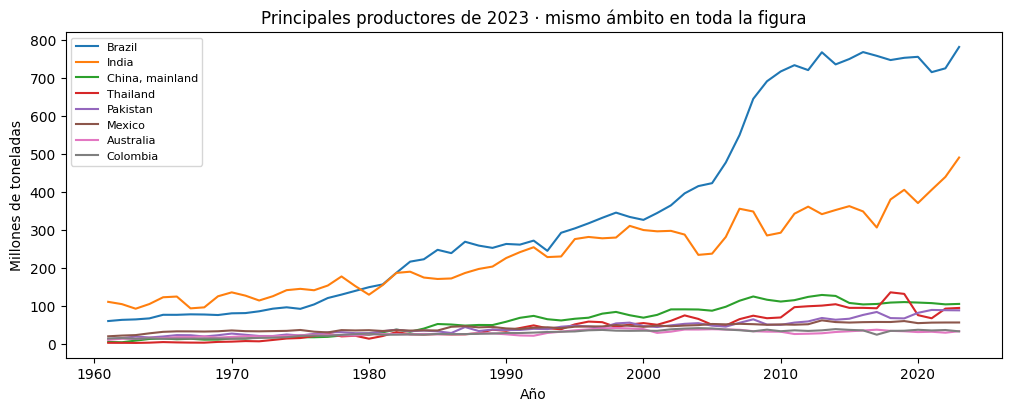

In [3]:
balance = pd.read_csv(salida / 'balance_mundial.csv')
balance_periodo = balance[balance.ano.between(1961,2023)]
print('Máxima diferencia relativa mundial 1961–2023:', balance_periodo.diferencia_relativa.abs().max())
print('Máxima diferencia China/componentes:', balance_periodo.china_menos_componentes_t.abs().max())
display(balance.tail(3))
produccion = paises[paises.elemento.eq('Production')]
top = produccion[produccion.ano.eq(2023)].nlargest(8,'valor').area
assert 'China' not in top.values
fig, ax = plt.subplots(figsize=(10,4), constrained_layout=True)
for area in top:
    g = produccion[produccion.area.eq(area)]
    ax.plot(g.ano,g.valor/1e6,label=area)
ax.set(xlabel='Año',ylabel='Millones de toneladas',title='Principales productores de 2023 · mismo ámbito en toda la figura')
ax.legend(fontsize=8)
fig.savefig(salida / 'productores_sin_solapamientos.png',dpi=150)
plt.show()

## Consistencia aritmética y extremos

La identidad esperada es producción (t) = área (ha) × rendimiento (kg/ha) / 1000. Se conservan tripletas incompletas y se distinguen de las comparables. Una discrepancia >1 % sirve para priorizar revisión, **sin definir invalidez**.

En áreas pequeñas, redondear hectáreas a enteros puede generar diferencias relativas grandes. Se calcula el área implícita producción×1000/rendimiento y su distancia al área publicada. Una distancia ≤0.5 ha es compatible con ese supuesto de redondeo, sin demostrar que ése sea el protocolo utilizado. El percentil 99 de rendimiento solo marca observaciones; ni E/I ni un extremo prueban un error. No se sustituyen ceros por faltantes de forma automática.

In [4]:
marcas = coherencia[coherencia.en_ambito_paises & coherencia.revisar]
display(marcas.groupby('area').agg(casos=('ano','size'), max_error_relativo=('error_relativo','max'), compatibles_redondeo=('compatible_redondeo_area_1ha','sum')))
display(marcas[['area','ano','Area harvested','Production','Yield','error_relativo','distancia_area_implicita_ha']].head(12))
extremos = pd.read_csv(salida / 'extremos_rendimiento.csv')
display(extremos[['area','ano','valor','flag']].nlargest(10,'valor'))
print('Exclusiones por error demostrado:',resumen['exclusiones_por_error'])

,casos,max_error_relativo,compatibles_redondeo
area,,,
Bhutan,24,0.076063,24
Djibouti,33,0.285764,33
French Polynesia,1,0.010879,1
Kuwait,3,1.000000,3
Spain,2,0.065135,2


elemento,area,ano,Area harvested,Production,Yield,error_relativo,distancia_area_implicita_ha
543,Bhutan,1992,27.0,971.06,36406.8,0.012279,0.327510
544,Bhutan,1993,25.0,953.40,37573.9,0.014739,0.373996
545,Bhutan,1994,24.0,937.26,38388.8,0.016995,0.414934
546,Bhutan,1995,24.0,922.42,39026.5,0.015412,0.364265
548,Bhutan,1997,22.0,896.03,40115.5,0.015054,0.336254
549,Bhutan,1998,22.0,884.34,40632.4,0.010825,0.235595
550,Bhutan,1999,21.0,873.63,41145.4,0.010962,0.232750
551,Bhutan,2000,21.0,863.98,41657.8,0.012539,0.260067
552,Bhutan,2001,20.0,855.51,42170.9,0.014134,0.286738
554,Bhutan,2003,20.0,843.81,43201.3,0.023958,0.467949


,area,ano,valor,flag
26,Indonesia,1971,158125.4,E
32,Peru,1972,156923.2,A
30,Indonesia,1972,155743.3,E
28,Peru,1971,155730.7,A
9,Peru,1965,155536.1,E
1,Peru,1961,154491.7,E
35,Peru,1973,153386.1,A
3,Peru,1962,153208.7,E
38,Peru,1974,151129.6,A
7,Peru,1964,150180.8,E


Exclusiones por error demostrado: 0


## Guatemala y preparación para segmentar

La trayectoria se muestra en las unidades confirmadas de la fuente y en el periodo requerido. Aún no se identifican pares ni se eligen variables/clusters: para ello se definirán ventanas comparables y sensibilidad a calidad/cobertura, conservando las marcas anteriores. La identidad producción/área/rendimiento también advierte que las tres dimensiones no son independientes.

,elemento,unidad,valor,flag
26922,Area harvested,ha,241000.0,A
26923,Yield,kg/ha,99467.8,A
26924,Production,t,23971750.0,A


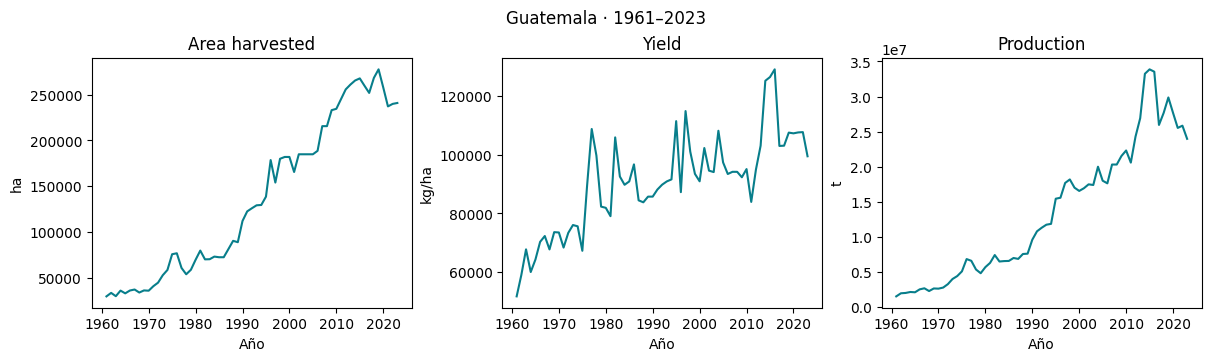

In [5]:
guatemala = paises[paises.area.eq('Guatemala')]
display(guatemala[guatemala.ano.eq(2023)][['elemento','unidad','valor','flag']])
fig, axes = plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
for ax, elemento, unidad in zip(axes,['Area harvested','Yield','Production'],['ha','kg/ha','t']):
    g = guatemala[guatemala.elemento.eq(elemento)]
    ax.plot(g.ano,g.valor,color='#087e8b')
    ax.set(title=elemento,xlabel='Año',ylabel=unidad)
fig.suptitle('Guatemala · 1961–2023')
fig.savefig(salida / 'guatemala_trayectoria.png',dpi=150)
plt.show()
assert resumen['celdas_paises'] + resumen['celdas_fuera_ambito'] == resumen['celdas_totales']
assert resumen['NOFLAG_coincide'] and resumen['flags_revisar'] == 0

## Conclusión y decisión para avanzar

Se corrigieron el conteo de países de baja cobertura, el denominador de calidad, los filtros inconsistentes y la inclusión involuntaria de 2024. Se verificaron unidades, identidad de las dos versiones, conservación y agregación mundial. El resultado permite continuar con **ETL y segmentación exploratoria**, usando el ámbito explícito y un análisis de cobertura/flags; no certifica exactitud agronómica de cada dato.

Se conservan ceros, ausencias y extremos con sus marcas. La próxima unidad es definir una representación comparable de países y ubicar Guatemala, sin sumar territorios solapados ni completar trayectorias artificialmente. No se infiere renovación o causalidad a partir de estas series nacionales.

Para precios, la descarga está completa pero el enlace/ajuste de contratos de Sugar_data.csv sigue pendiente de auditoría específica antes de interpretar saltos o entrenar pronósticos. Los outputs anteriores a esta revisión se consideran históricos; la evidencia vigente de este EDA está en **outputs/serie3_eda/revision/**.